# PCA for FD001 RUL Prediction

This notebook explains the existing PCA experiment and displays its saved results. It fits preprocessing transforms for the explained-variance demonstration using training engines only. It does not train models or write files.

## Introduction to PCA

Principal Component Analysis (PCA) makes new numeric features from weighted combinations of the input features. It orders these components by how much variance they explain. PCA is dimensionality reduction, not a way to select individual sensors.

## Why use PCA here?

The PCA experiment starts with sensor measurements and compresses their variation into fewer components. Several sensors in this dataset are constant, so the count of input columns is not the same as the number of varying measurements. The notebook checks this from the data before interpreting the result.

## Dataset overview: FD001

FD001 is simulated turbofan run-to-failure data with one operating condition and one fault mode. Training engines run to failure; official test RUL labels describe life remaining at the end of each observed test sequence. The cells below read local data and print the observed dimensions.

## Sensor features

The raw files contain 21 sensor columns. The code counts unique values for each sensor in the raw training file. A sensor with one unique value is constant in this dataset; a sensor with two values is described as having two distinct values, not as constant.

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler

project_root = Path.cwd().resolve()
while not (project_root / "data" / "raw" / "train_FD001.txt").is_file():
    if project_root.parent == project_root:
        raise FileNotFoundError("Could not locate data/raw/train_FD001.txt")
    project_root = project_root.parent

raw_columns = [
    "unit_id", "cycle", "setting_1", "setting_2", "setting_3",
    *[f"sensor_{number}" for number in range(1, 22)],
]
sensor_columns = [f"sensor_{number}" for number in range(1, 22)]
raw_train = pd.read_csv(
    project_root / "data" / "raw" / "train_FD001.txt",
    sep=r"\s+", header=None, names=raw_columns,
)
raw_test = pd.read_csv(
    project_root / "data" / "raw" / "test_FD001.txt",
    sep=r"\s+", header=None, names=raw_columns,
)
official_test_rul = pd.read_csv(
    project_root / "data" / "raw" / "RUL_FD001.txt",
    sep=r"\s+", header=None, names=["RUL"],
)["RUL"]
labeled_train = pd.read_csv(
    project_root / "data" / "processed" / "train_FD001_labeled.csv"
)

print(f"Raw training data: {raw_train.shape}; engines: {raw_train['unit_id'].nunique()}")
print(f"Raw test data: {raw_test.shape}; engines: {raw_test['unit_id'].nunique()}")
print(f"Official test RUL labels: {len(official_test_rul)}")
print(f"Labeled training data: {labeled_train.shape}")

sensor_unique_counts = raw_train[sensor_columns].nunique(dropna=False)
constant_sensors = sensor_unique_counts[sensor_unique_counts == 1].index.tolist()
two_value_sensors = sensor_unique_counts[sensor_unique_counts == 2].index.tolist()
sensor_summary = pd.DataFrame({"unique_values": sensor_unique_counts})
sensor_summary["status"] = np.where(
    sensor_summary["unique_values"].eq(1),
    "constant",
    np.where(sensor_summary["unique_values"].eq(2), "two distinct values", "varies"),
)
display(sensor_summary)
print(f"Constant sensors in the raw training data: {constant_sensors}")
print(f"Sensors with exactly two distinct values: {two_value_sensors}")

assert len(sensor_columns) == 21
assert set(constant_sensors) == {
    "sensor_1", "sensor_5", "sensor_10", "sensor_16", "sensor_18", "sensor_19"
}
assert sensor_unique_counts["sensor_6"] == 2

Raw training data: (20631, 26); engines: 100
Raw test data: (13096, 26); engines: 100
Official test RUL labels: 100
Labeled training data: (20631, 27)


,unique_values,status
sensor_1,1,constant
sensor_2,310,varies
sensor_3,3012,varies
sensor_4,4051,varies
sensor_5,1,constant
sensor_6,2,two distinct values
sensor_7,513,varies
sensor_8,53,varies
sensor_9,6403,varies
sensor_10,1,constant


Constant sensors in the raw training data: ['sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']
Sensors with exactly two distinct values: ['sensor_6']


## Preprocessing without engine leakage

Rows from the same engine must stay together. We first split unique engine IDs into training and validation groups. The scaler and PCA are then fitted only on rows belonging to training engines. Validation rows are transformed using those fitted objects, never used to fit them.

## StandardScaler

StandardScaler subtracts the training-data mean and divides by its standard deviation for each input feature. Fitting it before the engine split would let validation data influence preprocessing; this notebook fits it after the engine split.

In [2]:
from sklearn.model_selection import GroupShuffleSplit

if labeled_train.shape != (20631, 27):
    raise ValueError(f"Unexpected labeled training shape: {labeled_train.shape}")
if not set(sensor_columns).issubset(labeled_train.columns):
    raise ValueError("Labeled training CSV is missing sensor columns")

engine_ids = np.sort(labeled_train["unit_id"].unique())
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_engine_positions, validation_engine_positions = next(
    splitter.split(engine_ids, groups=engine_ids)
)
train_engine_ids = engine_ids[train_engine_positions]
validation_engine_ids = engine_ids[validation_engine_positions]
assert set(train_engine_ids).isdisjoint(validation_engine_ids)

train_rows = labeled_train["unit_id"].isin(train_engine_ids)
validation_rows = labeled_train["unit_id"].isin(validation_engine_ids)
scaler = StandardScaler()
scaler.fit(labeled_train.loc[train_rows, sensor_columns])
scaled_training_sensors = scaler.transform(
    labeled_train.loc[train_rows, sensor_columns]
)
scaled_validation_sensors = scaler.transform(
    labeled_train.loc[validation_rows, sensor_columns]
)

print(f"Training engines: {len(train_engine_ids)}")
print(f"Validation engines: {len(validation_engine_ids)}")
print(f"Engine overlap: {set(train_engine_ids).intersection(validation_engine_ids)}")
print(f"Scaler fit rows (training engines only): {scaler.n_samples_seen_}")
print(f"Scaled training rows: {scaled_training_sensors.shape}")
print(f"Scaled validation rows: {scaled_validation_sensors.shape}")

Training engines: 80
Validation engines: 20
Engine overlap: set()
Scaler fit rows (training engines only): 16561.0
Scaled training rows: (16561, 21)
Scaled validation rows: (4070, 21)


## PCA transformation

PCA receives only the 21 sensor columns. It does not receive engine ID, cycle, operating settings, or RUL. Here PCA is fitted only on the already-scaled training-engine rows; the validation data is transformed afterward.

In [3]:
pca = PCA(n_components=0.95, svd_solver="full")
pca.fit(scaled_training_sensors)
training_pca = pca.transform(scaled_training_sensors)
validation_pca = pca.transform(scaled_validation_sensors)

cumulative_explained_variance = np.cumsum(pca.explained_variance_ratio_)
component_count_95 = int(
    np.searchsorted(cumulative_explained_variance, 0.95, side="left") + 1
)
print(f"PCA input columns: {pca.n_features_in_}")
print(f"PCA components retained: {pca.n_components_}")
print(f"Cumulative explained variance retained: {cumulative_explained_variance[-1]:.6f}")
print(f"Training PCA shape: {training_pca.shape}")
print(f"Validation PCA shape: {validation_pca.shape}")
assert component_count_95 == pca.n_components_

saved_pca_path = project_root / "models" / "pca_fd001.pkl"
if saved_pca_path.is_file():
    saved_pca = joblib.load(saved_pca_path)
    saved_component_count = int(saved_pca.n_components_)
    component_counts_differ = component_count_95 != saved_component_count
    print(f"Saved experiment PCA components: {saved_component_count}")
    print(f"Computed and saved component counts differ: {component_counts_differ}")
else:
    saved_component_count = None
    component_counts_differ = None
    print("Saved experiment PCA artifact is missing; component counts cannot be compared.")

PCA input columns: 21
PCA components retained: 10
Cumulative explained variance retained: 0.951594
Training PCA shape: (16561, 10)
Validation PCA shape: (4070, 10)


Saved experiment PCA components: 10
Computed and saved component counts differ: False


## Explained variance

The plot shows each retained component's explained variance and the cumulative total. The dashed line marks the 95% target. The fitted PCA uses training-engine sensor data only.

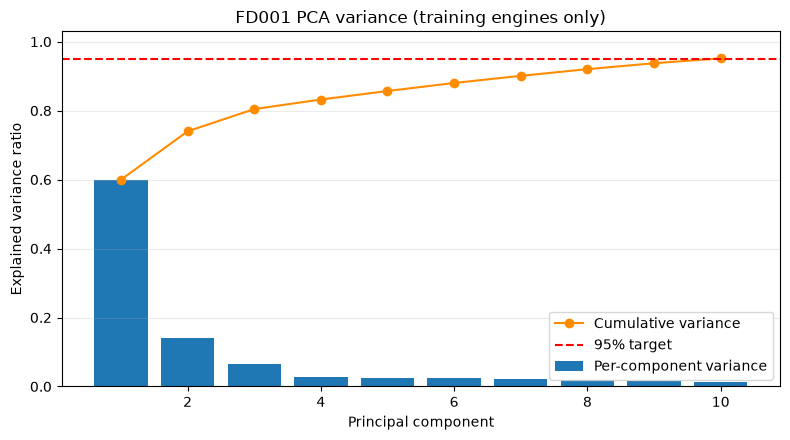

In [4]:
component_numbers = np.arange(1, len(cumulative_explained_variance) + 1)
figure, axis = plt.subplots(figsize=(8, 4.5))
axis.bar(component_numbers, pca.explained_variance_ratio_, label="Per-component variance")
axis.plot(
    component_numbers,
    cumulative_explained_variance,
    marker="o",
    color="darkorange",
    label="Cumulative variance",
)
axis.axhline(0.95, color="red", linestyle="--", label="95% target")
axis.set(
    xlabel="Principal component",
    ylabel="Explained variance ratio",
    title="FD001 PCA variance (training engines only)",
)
axis.set_ylim(0, 1.03)
axis.grid(axis="y", alpha=0.25)
axis.legend()
figure.tight_layout()
plt.show()
plt.close(figure)

## Component selection at 95%

The next output calculates the first component count whose cumulative explained variance reaches the target and compares it with the saved PCA experiment. This is computed from the current training-engine split, not typed in as a result.

In [5]:
first_component_at_95 = int(
    np.flatnonzero(cumulative_explained_variance >= 0.95)[0] + 1
)
print(f"First component count reaching 95%: {first_component_at_95}")
if saved_component_count is not None:
    if first_component_at_95 == saved_component_count:
        print("The computed count matches the saved experiment.")
    else:
        print("The computed count differs from the saved experiment.")
        print("The saved run and this split/data fit should be checked before interpreting the difference.")

First component count reaching 95%: 10
The computed count matches the saved experiment.


## Original features and PCA components

PCA starts with 21 sensor columns, but six are constant in the raw training data and have zero variance. Do not interpret the component count as compressing 21 fully varying measurements. Sensor 6 has two distinct values, so it is not constant. The PCA input includes sensor 6; the original 14-sensor baseline excludes it. PCA components combine sensor columns and are not sensor names.

## Models evaluated

- **Ridge Regression:** a linear baseline trained on the final timestep of each window.
- **SimpleRNN:** a recurrent neural network that processes the ordered window.
- **LSTM:** a recurrent model with gated memory for sequence information.

This notebook only describes existing model results. It does not train or retrain any model.

## Evaluation metrics

- **RMSE:** square root of the mean squared prediction error.
- **MAE:** mean absolute prediction error.
- **NASA score:** let `d = predicted RUL - true RUL`. For `d < 0`, penalty is `exp(-d/13) - 1`; for `d >= 0`, it is `exp(d/10) - 1`. Penalties are summed across test engines. Lower is better.

Notebook 02 reports both uncapped official test RUL and a separately capped-at-125 evaluation target. Its raw/uncapped test metrics use the official labels without applying the training cap.

## Results: original PCA run (single runs)

These CSV rows are individual results from the original PCA run. Ridge is deterministic; SimpleRNN and LSTM used different seeds. This is not a controlled, same-seed model ranking.

In [6]:
original_pca_results_path = project_root / "reports" / "pca_model_comparison.csv"
original_pca_results = pd.read_csv(original_pca_results_path)
expected_original_columns = {
    "model", "feature_representation", "pca_components",
    "cumulative_explained_variance", "window_length", "rmse", "mae", "nasa_score",
}
if set(original_pca_results.columns) != expected_original_columns:
    raise ValueError("Original PCA results CSV has an unexpected schema")
display(original_pca_results)
print("Original PCA run seeds: Ridge deterministic; SimpleRNN seed 42; LSTM seed 43.")

,model,feature_representation,pca_components,cumulative_explained_variance,window_length,rmse,mae,nasa_score
0,Ridge,PCA-transformed 21 sensors (95% variance),10,0.951594,30,21.709157,17.444019,1079.858901
1,SimpleRNN,PCA-transformed 21 sensors (95% variance),10,0.951594,30,20.116517,15.052484,1141.145067
2,LSTM,PCA-transformed 21 sensors (95% variance),10,0.951594,30,15.996947,11.675745,670.795664


Original PCA run seeds: Ridge deterministic; SimpleRNN seed 42; LSTM seed 43.


## Results: fair comparison (mean and standard deviation)

This separate CSV contains three runs for each neural model and one deterministic run for each Ridge model. The table below computes means and sample standard deviations across the available runs. Single-run Ridge results have no estimated standard deviation.

In [7]:
fair_results_path = project_root / "reports" / "fd001_fair_comparison.csv"
fair_results = pd.read_csv(fair_results_path)
metric_columns = ["rmse", "mae", "nasa_score"]
fair_summary = (
    fair_results.groupby("model", sort=False)
    .agg(
        runs=("run_seed", "count"),
        rmse_mean=("rmse", "mean"), rmse_sd=("rmse", "std"),
        mae_mean=("mae", "mean"), mae_sd=("mae", "std"),
        nasa_score_mean=("nasa_score", "mean"), nasa_score_sd=("nasa_score", "std"),
    )
    .reset_index()
)
display(fair_results)
display(fair_summary)
print("Fair comparison seed counts:")
display(fair_results.groupby("model", sort=False)["run_seed"].apply(list).rename("seeds"))

,model,feature_representation,pca_components,window_length,run_seed,rmse,mae,nasa_score
0,Original 14-sensor Ridge (retrained),14 selected sensors + MinMaxScaler,NaN,30,deterministic,21.607243,17.326797,1087.163494
1,PCA Ridge,21 sensors -> StandardScaler -> PCA,10.0,30,deterministic,21.709157,17.444019,1079.858901
2,Original 14-sensor LSTM,14 selected sensors + MinMaxScaler,NaN,30,42,14.993410,11.069129,386.341491
3,Original 14-sensor LSTM,14 selected sensors + MinMaxScaler,NaN,30,43,14.680767,11.039498,389.539858
4,Original 14-sensor LSTM,14 selected sensors + MinMaxScaler,NaN,30,44,14.988765,11.357522,365.155819
5,PCA SimpleRNN,21 sensors -> StandardScaler -> PCA,10.0,30,42,20.116518,15.052484,1141.145388
6,PCA SimpleRNN,21 sensors -> StandardScaler -> PCA,10.0,30,43,19.473842,14.224621,1097.575168
7,PCA SimpleRNN,21 sensors -> StandardScaler -> PCA,10.0,30,44,17.802772,12.931655,727.220949
8,PCA LSTM,21 sensors -> StandardScaler -> PCA,10.0,30,42,14.781389,11.520009,358.552438
9,PCA LSTM,21 sensors -> StandardScaler -> PCA,10.0,30,43,15.996947,11.675745,670.795667


,model,runs,rmse_mean,rmse_sd,mae_mean,mae_sd,nasa_score_mean,nasa_score_sd
0,Original 14-sensor Ridge (retrained),1,21.607243,NaN,17.326797,NaN,1087.163494,NaN
1,PCA Ridge,1,21.709157,NaN,17.444019,NaN,1079.858901,NaN
2,Original 14-sensor LSTM,3,14.887647,0.179179,11.155383,0.175683,380.345722,13.251689
3,PCA SimpleRNN,3,19.131044,1.194357,14.069587,1.068881,988.647169,227.447449
4,PCA LSTM,3,15.476682,0.626395,11.709184,0.207922,494.557044,159.962622


Fair comparison seed counts:


model
Original 14-sensor Ridge (retrained)    [deterministic]
PCA Ridge                               [deterministic]
Original 14-sensor LSTM                    [42, 43, 44]
PCA SimpleRNN                              [42, 43, 44]
PCA LSTM                                   [42, 43, 44]
Name: seeds, dtype: object

## Charts: original PCA and fair comparison

For the fair comparison, bars show the mean and neural-model error bars show the sample standard deviation. Original PCA bars are single-run results, and deterministic Ridge has no seed variation estimate.

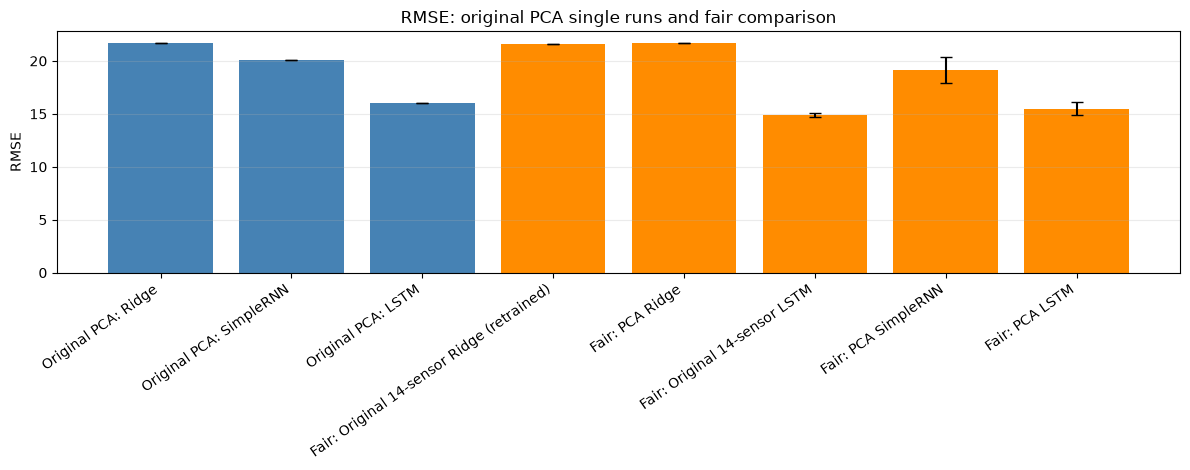

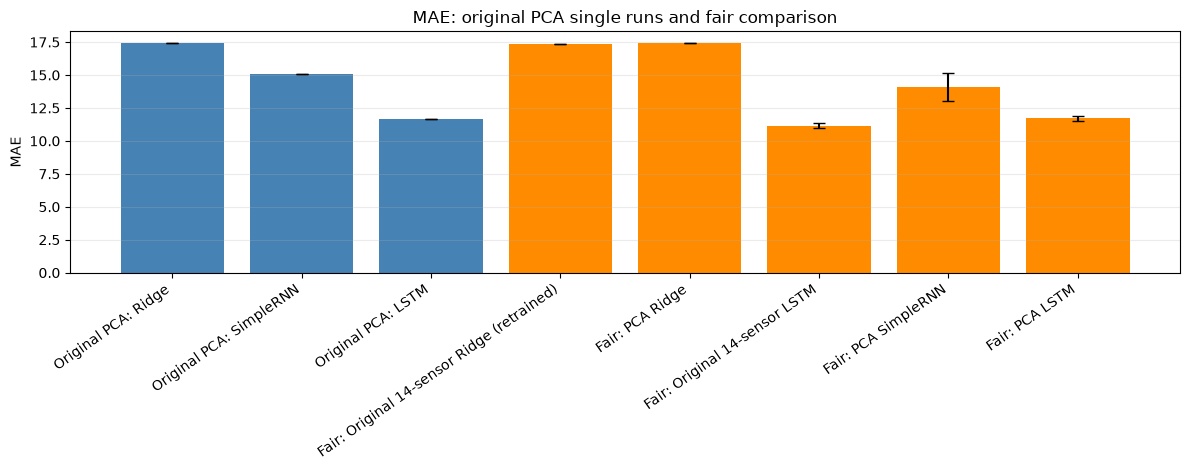

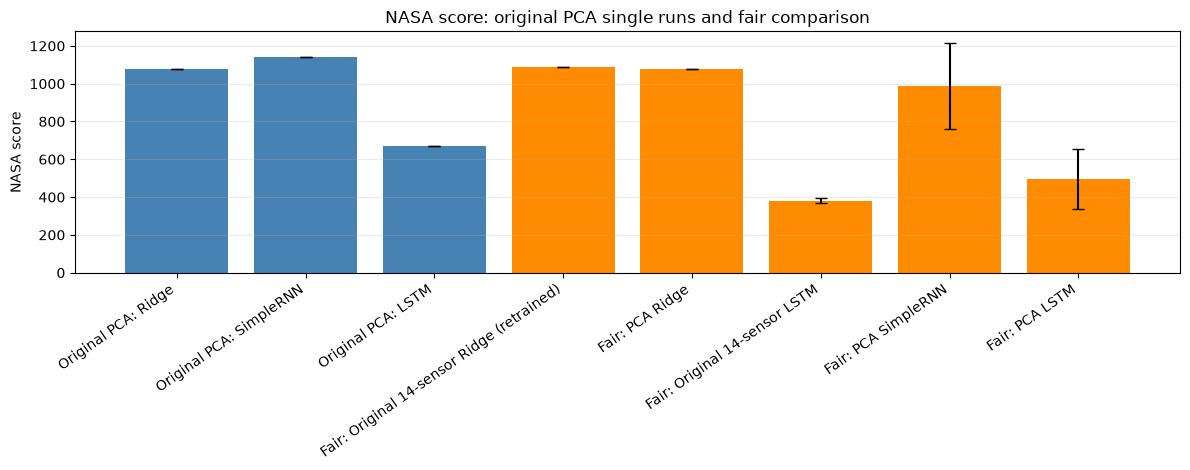

In [8]:
original_labels = [f"Original PCA: {name}" for name in original_pca_results["model"]]
fair_labels = [f"Fair: {name}" for name in fair_summary["model"]]
labels = original_labels + fair_labels

for metric, mean_column, sd_column, title in (
    ("rmse", "rmse_mean", "rmse_sd", "RMSE"),
    ("mae", "mae_mean", "mae_sd", "MAE"),
    ("nasa_score", "nasa_score_mean", "nasa_score_sd", "NASA score"),
):
    original_values = original_pca_results[metric].to_numpy(dtype=float)
    fair_values = fair_summary[mean_column].to_numpy(dtype=float)
    fair_sd = fair_summary[sd_column].fillna(0).to_numpy(dtype=float)
    values = np.concatenate([original_values, fair_values])
    errors = np.concatenate([np.zeros(len(original_values)), fair_sd])
    figure, axis = plt.subplots(figsize=(12, 4.8))
    colors = ["steelblue"] * len(original_values) + ["darkorange"] * len(fair_values)
    axis.bar(np.arange(len(labels)), values, yerr=errors, capsize=4, color=colors)
    axis.set_xticks(np.arange(len(labels)), labels, rotation=35, ha="right")
    axis.set_ylabel(title)
    axis.set_title(f"{title}: original PCA single runs and fair comparison")
    axis.grid(axis="y", alpha=0.25)
    figure.tight_layout()
    plt.show()
    plt.close(figure)

## Interpretation

Use the displayed tables for the exact metrics. The original PCA table contains one result per model, while the fair-comparison table reports run-level values and the summary reports means and standard deviations. Differences between those tables can reflect both the model runs and their protocol; the original PCA rows alone do not establish a fair model ranking.

## Limitations

- This analysis uses FD001 simulated data and one fault mode; it does not establish performance on real engines or other subsets.
- Six PCA input sensors have zero variance, so counting all input columns as informative would overstate the reduction.
- The original PCA results are single runs with different neural seeds. The fair comparison reports three neural seeds; Ridge is a single deterministic run.
- The original PCA run and fair comparison have different protocols and should be identified separately.
- Notebook 01 fits its scaler before its later engine split, exposing validation-engine feature ranges to preprocessing. Its results are exploratory; this notebook's demonstration fits transforms after the engine split.
- Notebook 02's LSTM test path uses seeds 42, 43, and 44 when seed-42 training finishes under its runtime threshold; otherwise it uses seed 42 alone. It evaluates both raw official RUL and a separately capped target.

## Conclusion

This notebook demonstrates a training-only PCA workflow and reads existing result files without retraining. Interpret the original PCA and fair-comparison results as separate experiments, and use the computed variance output to describe the retained components.

## References

- Saxena et al. (2008), PHM08: damage propagation modelling for run-to-failure simulation.
- Heimes (2008), recurrent neural networks for remaining useful life estimation.
- Zheng et al. (2017), LSTM networks for remaining useful life estimation.
- Ramasso & Saxena, *International Journal of Prognostics and Health Management* (IJPHM).